# Analyse descriptive

Question : le taux d'obésité d'un département est-il lié à sa pauvreté, à l'accès aux médecins, aux fast-foods ou aux salles de sport ?

Ce notebook décrit les données de la table `data/processed/departements.csv` (96 départements de France métropolitaine).

## 1. Chargement

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/departements.csv", dtype={"dep": str, "region": str})
print(df.shape)
print("valeurs manquantes :", df.isna().sum().sum())

(96, 17)
valeurs manquantes : 0


Les codes du département et de la région sont lus comme du texte (`dtype={"dep": str, "region": str}`), sinon `01` deviendrait `1` et `2A` ne serait pas reconnu.

**Constat :** la table contient 96 départements et 17 colonnes, sans aucune valeur manquante.

## 2. Statistiques descriptives

In [2]:
variables = [
    "obesite",
    "taux_pauvrete",
    "niveau_vie_median",
    "apl",
    "restauration_10k",
    "salles_sport_10k",
    "fastfoods_10k",
    "densite",
    "part_60_plus",
]
df[variables].describe().round(1)

,obesite,taux_pauvrete,niveau_vie_median,apl,restauration_10k,salles_sport_10k,fastfoods_10k,densite,part_60_plus
count,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0
mean,15.8,14.9,22706.7,3.6,32.7,1.4,4.3,567.2,29.7
std,3.2,3.0,1721.9,0.6,14.3,0.6,1.6,2398.4,4.8
min,7.8,9.1,19020.0,2.4,18.2,0.6,2.0,14.8,17.5
25%,13.4,12.6,21575.0,3.1,24.0,1.0,3.2,49.6,26.7
50%,16.0,14.8,22285.0,3.6,27.9,1.2,3.9,82.9,29.5
75%,18.0,16.2,23292.5,4.1,37.8,1.5,4.9,164.2,33.4
max,23.3,28.4,29730.0,5.2,98.0,4.9,13.9,19967.5,39.5


**Interprétation :**

- **Obésité :** 15,8 % en moyenne (médiane 16,0 %), avec un écart-type de 3,2 points. Elle va de 7,8 % (Hautes-Alpes) à 23,3 % (Orne), soit plus de 15 points d'écart. Ces valeurs viennent d'une enquête, donc elles ont une marge d'erreur d'environ ±3 points : les départements aux extrémités sont à interpréter avec prudence.
- **Pauvreté :** 14,9 % en moyenne, de 9,1 % (Vendée) à 28,4 % (Seine-Saint-Denis). Les trois quarts des départements sont sous 16,2 %, donc la Seine-Saint-Denis est très au-dessus des autres.
- **Densité :** très asymétrique. La moyenne (567 hab/km²) est bien au-dessus de la médiane (83 hab/km²), parce que Paris dépasse 19 900 hab/km².
- **Fast-foods :** 4,3 pour 10 000 habitants en moyenne, avec un maximum de 13,9 à Paris. La restauration et les salles de sport ont aussi quelques valeurs très élevées.

## 3. Distributions

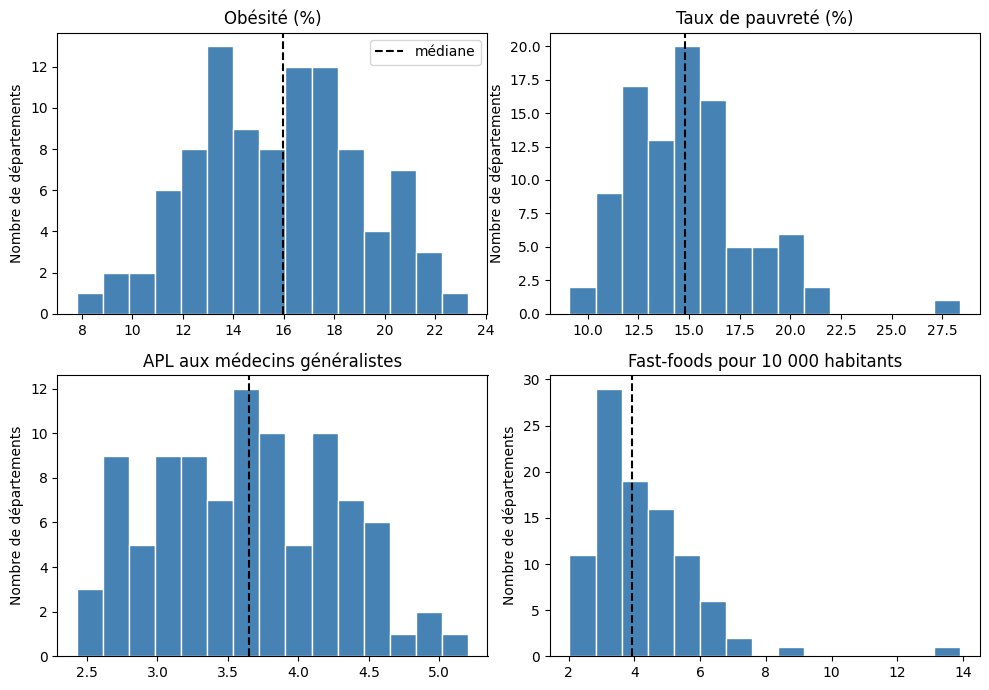

In [3]:
a_tracer = {
    "obesite": "Obésité (%)",
    "taux_pauvrete": "Taux de pauvreté (%)",
    "apl": "APL aux médecins généralistes",
    "fastfoods_10k": "Fast-foods pour 10 000 habitants",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (colonne, titre) in zip(axes.flat, a_tracer.items()):
    ax.hist(df[colonne], bins=15, color="steelblue", edgecolor="white")
    ax.axvline(df[colonne].median(), color="black", linestyle="--", label="médiane")
    ax.set_title(titre)
    ax.set_ylabel("Nombre de départements")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("../figures/desc_distributions.png", dpi=150)
plt.show()

**Interprétation :**

- **Obésité :** la distribution est assez symétrique, centrée autour de 16 %, sans valeur isolée. La plupart des départements sont entre 12 % et 20 %.
- **Pauvreté :** la plupart des départements sont entre 10 % et 20 %. La distribution s'étire vers la droite et un département est isolé autour de 28 % (la Seine-Saint-Denis).
- **APL :** les valeurs sont réparties de façon assez régulière entre 2,4 et 5,2, sans valeur extrême.
- **Fast-foods :** la distribution est très asymétrique. La plupart des départements ont entre 2 et 6 fast-foods pour 10 000 habitants, et quelques-uns sont très au-dessus, dont Paris à 13,9.

## 4. Départements extrêmes

In [4]:
import json

with open("../data/raw/departements.geojson", encoding="utf-8") as f:
    contours = json.load(f)
noms = {d["properties"]["code"]: d["properties"]["nom"] for d in contours["features"]}
df["nom"] = df["dep"].map(noms)

colonnes = ["nom", "obesite", "taux_pauvrete", "apl", "fastfoods_10k"]
df.sort_values("obesite", ascending=False)[colonnes].head(5).round(1)

,nom,obesite,taux_pauvrete,apl,fastfoods_10k
58,Orne,23.3,15.6,2.9,3.2
59,Pas-de-Calais,21.9,18.4,4.3,3.6
78,Ardennes,21.7,19.4,3.7,3.4
11,Aisne,21.4,18.8,3.2,2.7
30,Indre,21.2,15.4,2.8,3.3


In [5]:
df.sort_values("obesite")[colonnes].head(5).round(1)

,nom,obesite,taux_pauvrete,apl,fastfoods_10k
45,Hautes-Alpes,7.8,14.7,5.2,8.9
21,Corse-du-Sud,9.0,15.8,3.9,5.4
73,Paris,9.1,15.6,4.7,13.9
29,Ille-et-Vilaine,10.5,10.8,4.1,3.6
22,Haute-Corse,10.8,20.2,3.8,5.9


**Interprétation :**

- **Les plus touchés :** l'Orne (23,3 %), le Pas-de-Calais, les Ardennes, l'Aisne et l'Indre. Ce sont des départements du nord, de l'est et du centre, plutôt ruraux. Leur taux de pauvreté est variable (de 15,4 % à 19,4 %), mais leur nombre de fast-foods est faible (entre 2,7 et 3,6 pour 10 000 habitants).
- **Les moins touchés :** les Hautes-Alpes (7,8 %), la Corse-du-Sud, Paris, l'Ille-et-Vilaine et la Haute-Corse. Ce sont des départements touristiques, très urbains ou aisés, et plusieurs ont beaucoup de fast-foods (Paris 13,9 et Hautes-Alpes 8,9).
- Les départements où il y a le plus de fast-foods ne sont donc pas ceux où l'obésité est la plus forte. Cela ne veut pas dire que les fast-foods protègent : ces départements ont d'autres points communs (tourisme, population jeune ou aisée).